In [ ]:
import os
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
import joblib
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
DATA_PATH = os.path.join(os.getcwd(), '/content/Data')
LABELS = np.array(os.listdir(DATA_PATH))
LABELS_LEN = LABELS.shape[0]
PATHS = [os.path.join(DATA_PATH, label) for label in LABELS]
VALIDE_EXTENTIONS = ['.jpeg', '.jpg', '.bmp', '.png']
IMGS_SHAPE = ( 224, 224, 1 )
BATCH_SIZE = 64
AUTOTUNE = tf.data.AUTOTUNE
TOTAL_IMGS = sum(1  for path in PATHS for _ in os.listdir(path))
ALL_PATHS = np.array([os.path.join(path, img_name) for path in PATHS for img_name in os.listdir(path)])

In [ ]:
LABELS

array(['pituitary', 'glioma', 'meningioma', 'notumor'], dtype='<U10')

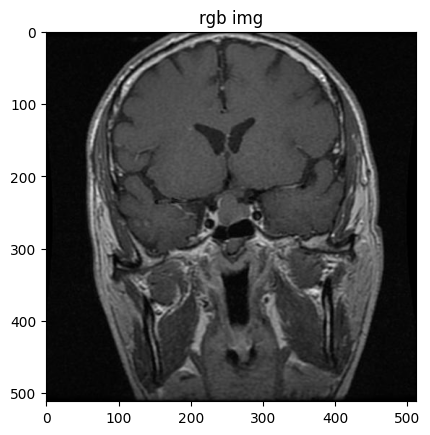

(512, 512)


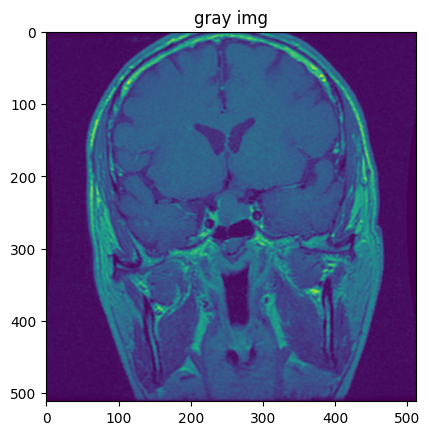

In [ ]:
img = cv.imread(os.path.join(PATHS[0], os.listdir(PATHS[0])[0]), cv.IMREAD_COLOR_RGB)
gray_img = cv.cvtColor(img, cv.COLOR_RGB2GRAY)
# _, (ax1, ax2) = plt.subplots(1, 2)
plt.imshow(img)
plt.title('rgb img')
plt.show()
plt.imshow(gray_img)
plt.title('gray img')
print(gray_img.shape)

In [ ]:
# imgs_dict = {}

# for label in LABELS:

#     label_path = os.path.join(DATA_PATH, label)
#     label_count = sum(1 for _ in os.scandir(label_path))
#     label_imgs = np.empty((224, 224, 3, label_count), dtype=np.uint8)
#     label_imgs_tr = np.empty((224, 224, 3, label_count), dtype=np.float16)

#     for id, img_name in enumerate(os.listdir(label_path)):

#         _, extention = os.path.splitext(os.path.join(label_path, img_name))
#         if not extention in VALIDE_EXTENTIONS: continue

#         img_path = os.path.join(label_path, img_name)
#         img = cv.imread(img_path, cv.IMREAD_COLOR_RGB)

#         if img is None:
#             img_path.unlink(missing_ok=True)

#         img = cv.resize(img, (224, 224))
#         transformed_img = cv.normalize(img, None, 0.0, 1.0, norm_type=cv.NORM_MINMAX, dtype=cv.CV_16F)

#         label_imgs[:, :, :, id] = np.uint8(img)
#         label_imgs_tr[:, :, :, id] = np.float16(transformed_img)

#     imgs_dict[label] = np.array([label_imgs, label_imgs_tr])

In [ ]:
def get_encoders():
  label_enc = {}
  labels_len = len(LABELS)

  for id, label in enumerate(LABELS):
    enc = np.zeros((labels_len, ), dtype='uint8')
    enc[id] = 1
    label_enc[str(label)] = enc
  rev_enc = {str(v): k for k, v in label_enc.items()}

  return label_enc, rev_enc

enc, rev_enc = get_encoders()

In [ ]:
def custom_data_generator(paths, target_size = (224, 224)):
  for path in paths:
    splits = path.split('/')
    label = splits[len(splits) - 2]
    img = cv.imread(path, cv.IMREAD_GRAYSCALE)
    if img is None:
        continue
    img = cv.resize(img, target_size)
    cv.normalize(img, img, 0.0, 1.0, cv.NORM_MINMAX, cv.CV_16F)
    img = np.expand_dims(img, axis=-1)
    yield img, enc[label]


In [ ]:
ids = np.arange(0, TOTAL_IMGS)
train_ids, test_ids = train_test_split(ids, test_size=0.2, random_state=42)

tf.keras.mixed_precision.set_global_policy("mixed_float16")
train_dataset = tf.data.Dataset.from_generator(lambda: custom_data_generator(ALL_PATHS[train_ids]), output_signature=(
    tf.TensorSpec(
        shape=IMGS_SHAPE, dtype=tf.float16
    ),
    tf.TensorSpec(
        shape=(LABELS_LEN, ), dtype=tf.uint8
    )
))

train_dataset = (
    train_dataset.batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

test_dataset = tf.data.Dataset.from_generator(lambda: custom_data_generator(ALL_PATHS[test_ids]), output_signature=(
    tf.TensorSpec(
        shape=IMGS_SHAPE, dtype=tf.float16
    ),
    tf.TensorSpec(
        shape=(LABELS_LEN, ), dtype=tf.uint8
    )
))

test_dataset = (
    test_dataset.batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

In [ ]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Conv2D(16, 3, activation='elu', input_shape=IMGS_SHAPE),
    tf.keras.layers.AvgPool2D(2),
    tf.keras.layers.Conv2D(32, 3, activation='elu', input_shape=IMGS_SHAPE),
    tf.keras.layers.AvgPool2D(2),
    tf.keras.layers.Conv2D(64, 3, activation='elu', input_shape=IMGS_SHAPE),
    tf.keras.layers.AvgPool2D(2),
    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation='elu'),
    tf.keras.layers.Dense(128, activation='elu'),
    tf.keras.layers.Dense(64, activation='elu'),
    tf.keras.layers.Dense(LABELS.shape[0], activation='softmax'),
])

model.compile(
    'adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
callbacks = [
    tf.keras.callbacks.ModelCheckpoint('model.{epoch:02d}-{val_loss:.2f}.keras'),
    tf.keras.callbacks.EarlyStopping(patience=3)
]

history = model.fit(train_dataset, validation_split=0.2, epochs=30, callbacks=callbacks)

Epoch 1/30


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


     88/Unknown 47s 275ms/step - accuracy: 0.3081 - loss: 7.9816

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


88/88 ━━━━━━━━━━━━━━━━━━━━ 56s 372ms/step - accuracy: 0.4089 - loss: 8.0123 - val_accuracy: 0.5907 - val_loss: 6.1356
Epoch 2/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 11s 120ms/step - accuracy: 0.6184 - loss: 5.6144 - val_accuracy: 0.6242 - val_loss: 5.8379
Epoch 3/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 11s 119ms/step - accuracy: 0.7807 - loss: 2.5847 - val_accuracy: 0.8278 - val_loss: 1.0556
Epoch 4/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 11s 119ms/step - accuracy: 0.8373 - loss: 0.5820 - val_accuracy: 0.8747 - val_loss: 0.3704
Epoch 5/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 10s 118ms/step - accuracy: 0.8952 - loss: 0.2868 - val_accuracy: 0.8840 - val_loss: 0.3083
Epoch 6/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 10s 118ms/step - accuracy: 0.9208 - loss: 0.2077 - val_accuracy: 0.9032 - val_loss: 0.2580
Epoch 7/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 10s 118ms/step - accuracy: 0.9475 - loss: 0.1463 - val_accuracy: 0.9210 - val_loss: 0.2390
Epoch 8/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 10s 118ms/step - accuracy: 0.9614 - loss: 0.1072 - val_accuracy: 0.931

/tmp/ipykernel_825/1859319404.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[id].legend()
/tmp/ipykernel_825/1859319404.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[id].legend()


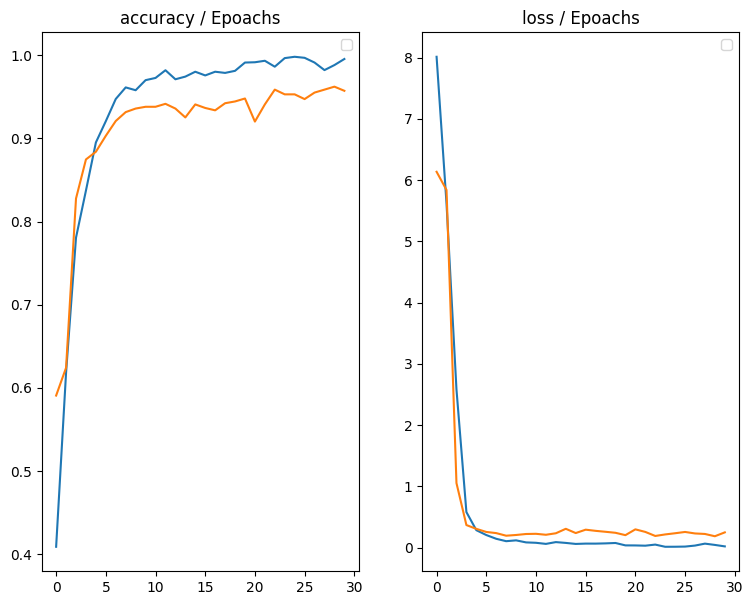

In [ ]:
_, axes = plt.subplots(1, 2, figsize=(9, 7))
for id, item in enumerate(['accuracy', 'loss']):
  sns.lineplot(history.history[item], ax=axes[id])
  sns.lineplot(history.history[f'val_{item}'], ax=axes[id])
  axes[id].set_title(f'{item} / Epoachs')
  axes[id].legend()

In [ ]:
model.save('/content/drive/MyDrive/neur_model/model.keras')

In [ ]:
model = tf.keras.models.load_model('/content/drive/MyDrive/neur_model/model.keras')

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 30 variables whereas the saved optimizer has 34 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [ ]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_9 (Conv2D)               │ (None, 222, 222, 16)   │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_9             │ (None, 111, 111, 16)   │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 109, 109, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_10            │ (None, 54, 54, 32)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 52, 52, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_11            │ (None, 26, 26, 64)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 43264)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │     5,537,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,758,734 (63.93 MB)

 Trainable params: 5,586,244 (21.31 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 11,172,490 (42.62 MB)

In [ ]:
y_pred = model.predict(test_dataset)
y_pred = np.argmax(y_pred, axis=1)

22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 92ms/step


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


In [ ]:
y_true_labels = [path.split('/')[-2] for path in ALL_PATHS[test_ids]]
label_to_id = {name: idx for idx, name in enumerate(LABELS)}
y_true = np.array([label_to_id[name] for name in y_true_labels])

In [ ]:
print(y_true.shape, y_pred.shape)

(1405,) (1405,)


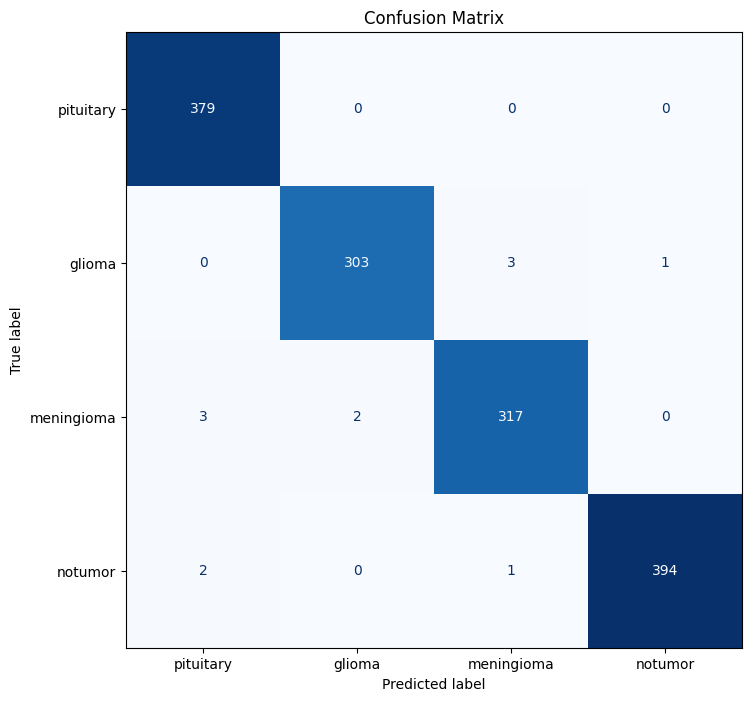

In [ ]:
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    display_labels=LABELS,
    cmap='Blues',
    ax= ax,
    colorbar=False
)
plt.title('Confusion Matrix')
plt.show()

In [ ]:
classification_rapport = classification_report(y_true, y_pred, output_dict=True)

In [ ]:
classification_rapport

{'0': {'precision': 0.9869791666666666,
  'recall': 1.0,
  'f1-score': 0.9934469200524246,
  'support': 379.0},
 '1': {'precision': 0.9934426229508196,
  'recall': 0.9869706840390879,
  'f1-score': 0.9901960784313726,
  'support': 307.0},
 '2': {'precision': 0.9875389408099688,
  'recall': 0.984472049689441,
  'f1-score': 0.9860031104199067,
  'support': 322.0},
 '3': {'precision': 0.9974683544303797,
  'recall': 0.9924433249370277,
  'f1-score': 0.9949494949494949,
  'support': 397.0},
 'accuracy': 0.9914590747330961,
 'macro avg': {'precision': 0.9913572712144587,
  'recall': 0.9909715146663892,
  'f1-score': 0.9911489009632997,
  'support': 1405.0},
 'weighted avg': {'precision': 0.9914836050265046,
  'recall': 0.9914590747330961,
  'f1-score': 0.9914551813725692,
  'support': 1405.0}}

In [ ]:
# _, axes = plt.subplots(ncols=4, figsize=(20, 20))
# # for id, label in enumerate(LABELS):
#     axes[id].imshow( imgs_dict[label][0][:, :, :, 0].astype(np.uint8) )
#     axes[id].set_title(f'First Image From {label} Class')

In [ ]:
labels_count = np.empty((4), dtype=np.uint16)

for id, label in enumerate(LABELS):
    labels_count[id] = len(imgs_dict[label][0][223, 223, 2, :].astype(np.uint8))

In [ ]:
sns.barplot(x=LABELS, y=labels_count)
plt.show()

In [ ]:
_, axes = plt.subplots(ncols=4, figsize=(20, 20))
for id, label in enumerate(LABELS):
    axes[id].imshow(imgs_dict[label][1][:, :, :, 0].astype(np.float32))
    axes[id].set_title(f'First Tr-Image From {label} Class')

In [ ]:
total_imgs = labels_count.sum(dtype=np.int16)
labels_arr = np.empty((total_imgs), dtype=LABELS.dtype)
imgs_arr = np.empty((224, 224, 3, total_imgs), dtype=np.float16)
start = 0
end = labels_count[0]

for id, label in enumerate(LABELS, start=1):
    end = labels_count[:id].sum()
    imgs_arr[:, :, :, id] = imgs_dict[label][1][:, :, :, 0]
    labels_arr[start:end] = label
    start = end

In [ ]:
# perm = np.random.permutation(total_imgs)
# X = imgs_arr[..., perm]
# # y = labels_arr[perm]

In [ ]:
indices = np.arange(0, total_imgs)
train_ids, test_ids = train_test_split(indices, test_size=0.2, random_state=40)

x_train = imgs_arr[..., train_ids]
x_test = imgs_arr[..., test_ids]

y_train = labels_arr[train_ids]
y_test = labels_arr[test_ids]